In [ ]:
import os
import gc
import math
import random
from pathlib import Path
from copy import deepcopy

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    average_precision_score,
    f1_score
)

In [34]:
import torch 
device = torch.device('cuda')
torch.cuda.is_available()

True

In [7]:
from pathlib import Path
import kagglehub
kagglehub.login()


In [9]:
folder = Path(kagglehub.competition_download('cifar100-image-classification-with-long-tail'))

100%|██████████| 90.4M/90.4M [00:06<00:00, 14.2MB/s]

Extracting files...


In [16]:
random.seed(11037)
np.random.seed(11037)
torch.manual_seed(11037)
torch.cuda.manual_seed_all(11037)

In [17]:
csv_file = "/home/hawk/.cache/kagglehub/competitions/cifar100-image-classification-with-long-tail/dataset/cifar100_lt/data/cifar100_lt.csv"
df = pd.read_csv(csv_file, names=["image_path", "label"], dtype= {'label':'string'})
df

,image_path,label
0,cifar100_lt/img/train/IZVAOjKdDk.png,tank
1,cifar100_lt/img/train/WtwhbjpuHX.png,turtle
2,cifar100_lt/img/train/EkklXXSQdD.png,lamp
3,cifar100_lt/img/train/PZVwJawtXT.png,trout
4,cifar100_lt/img/train/vsIhWjNxZc.png,aquarium_fish
...,...,...
38717,cifar100_lt/img/test/qrDVDyxElW.png,<NA>
38718,cifar100_lt/img/test/tgicpeCDVy.png,<NA>
38719,cifar100_lt/img/test/PouxAXQINO.png,<NA>
38720,cifar100_lt/img/test/wqtBuvYWOr.png,<NA>


In [ ]:
df["image_path"] = df["image_path"].str.replace("\\", "/", regex = False)

In [19]:
df = df[df["image_path"].str.contains("/train/", regex = False)].copy()
df = df.reset_index(drop=True)
df.head()

,image_path,label
0,cifar100_lt/img/train/IZVAOjKdDk.png,tank
1,cifar100_lt/img/train/WtwhbjpuHX.png,turtle
2,cifar100_lt/img/train/EkklXXSQdD.png,lamp
3,cifar100_lt/img/train/PZVwJawtXT.png,trout
4,cifar100_lt/img/train/vsIhWjNxZc.png,aquarium_fish


In [20]:
classes = sorted(df["label"].unique())
df["target"] = df["label"].map({label: i for i, label in enumerate(classes)}).astype(int)
df.head()

,image_path,label,target
0,cifar100_lt/img/train/IZVAOjKdDk.png,tank,85
1,cifar100_lt/img/train/WtwhbjpuHX.png,turtle,93
2,cifar100_lt/img/train/EkklXXSQdD.png,lamp,40
3,cifar100_lt/img/train/PZVwJawtXT.png,trout,91
4,cifar100_lt/img/train/vsIhWjNxZc.png,aquarium_fish,1


In [22]:
df["image_path"] = df["image_path"].apply(lambda p: str((folder / "dataset" / p).resolve()))

In [24]:
train_grp, test_grp = train_test_split(df, test_size=0.2, random_state=11037, stratify=df["target"])
train_grp = train_grp.reset_index(drop=True)
test_grp = test_grp.reset_index(drop=True)

In [25]:
train_grp.to_csv("train_grp.csv", index=False)
test_grp.to_csv("test_grp.csv", index=False)

Smallest class: 41
Largest class: 399
Imbalance ratio: 9.731707317073171


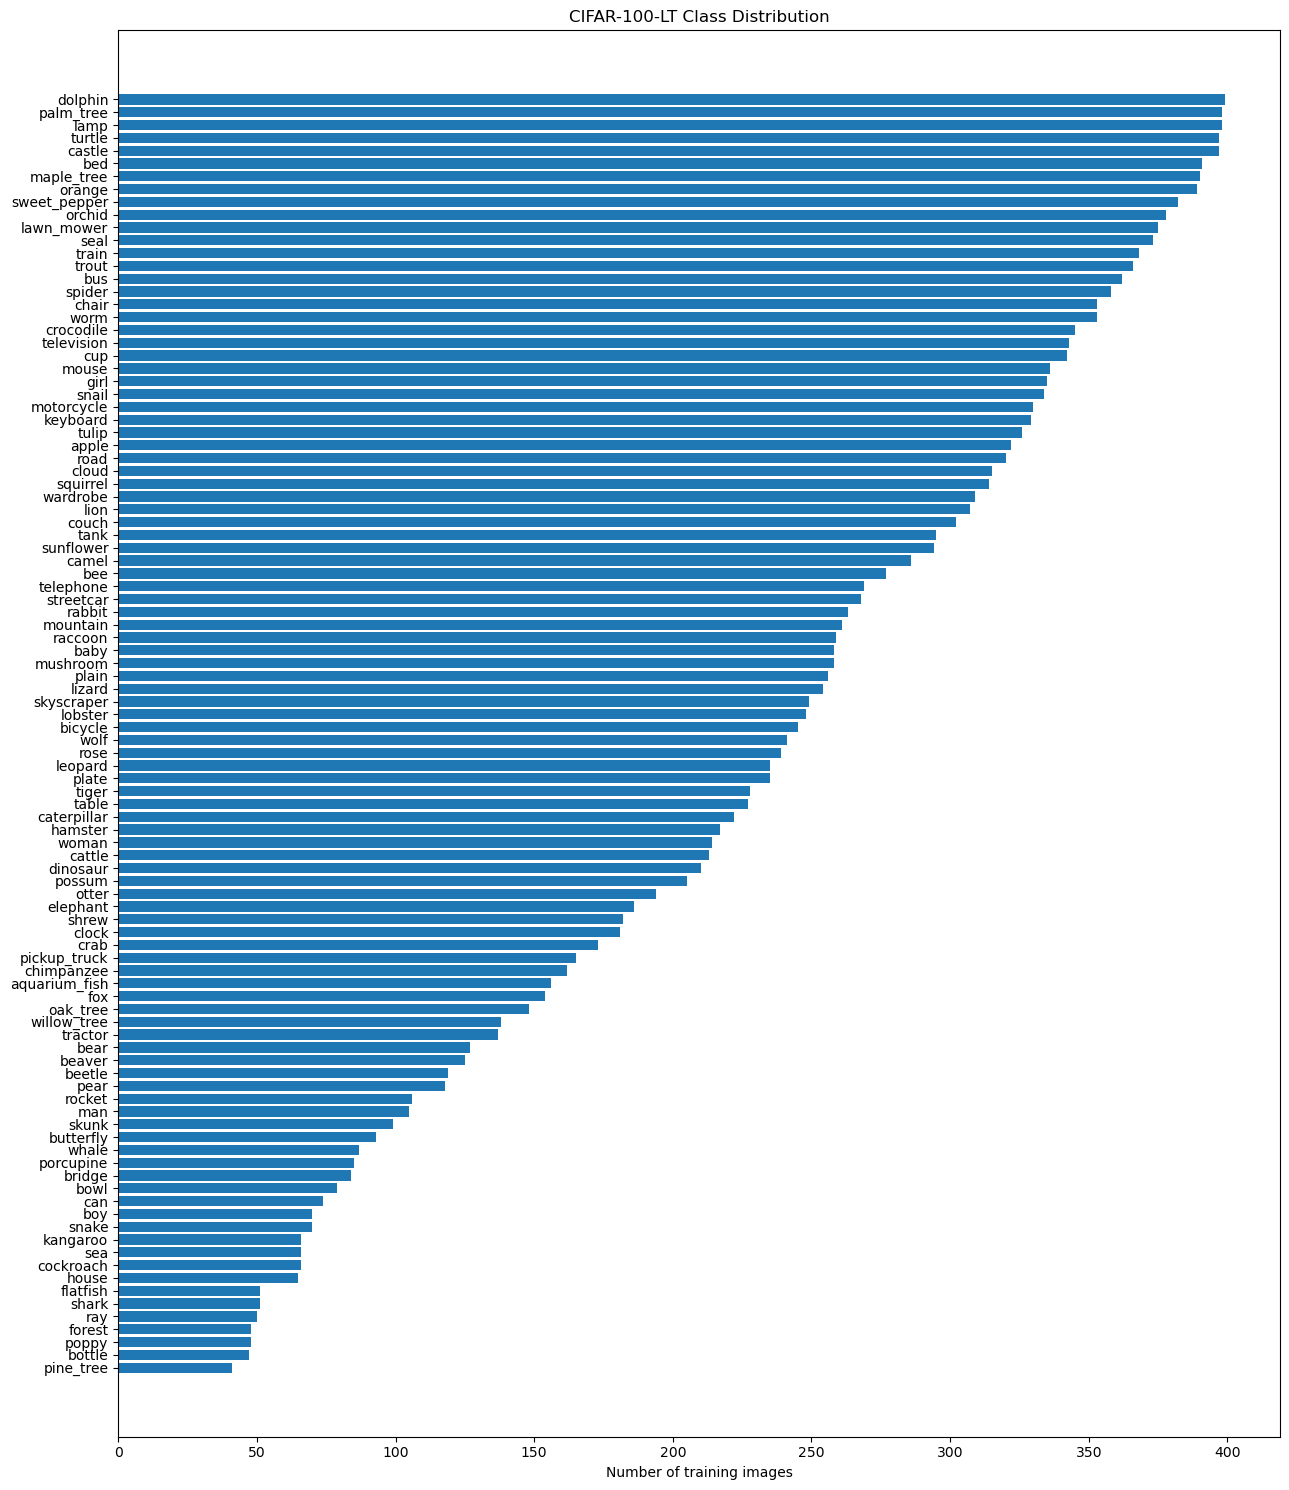

In [26]:
counts = train_grp["label"].value_counts().sort_values()

print("Smallest class:", counts.min())
print("Largest class:", counts.max())
print("Imbalance ratio:", counts.max() / counts.min())

plt.figure(figsize=(13, 15))
plt.barh(counts.index, counts.values)
plt.xlabel("Number of training images")
plt.title("CIFAR-100-LT Class Distribution")
plt.tight_layout()
plt.show()

In [27]:
train_transform = transforms.Compose([
                                        transforms.RandomCrop(32, padding=4),
                                        transforms.RandomHorizontalFlip(),
                                        transforms.ToTensor(),
                                        transforms.Normalize(
                                                                (0.5071, 0.4867, 0.4408),
                                                                (0.2675, 0.2565, 0.2761)
                                                                                            )
                                                                                                ])

test_transform = transforms.Compose([
                                        transforms.ToTensor(),
                                        transforms.Normalize(
                                                            (0.5071, 0.4867, 0.4408),
                                                            (0.2675, 0.2565, 0.2761)
                                                                                        )
                                                                                            ])

In [28]:
class CIFARDataset(Dataset):

    def __init__(self, table, transform):
        self.paths = table["image_path"].tolist()
        self.labels = table["target"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert("RGB")

        return self.transform(image), self.labels[index]

In [29]:
train_dataset = CIFARDataset(train_grp, train_transform)
image, label = train_dataset[0]

print(image.shape)
print(label)

torch.Size([3, 32, 32])
36


In [30]:
def make_loader(tabel, training = False):
    dataset = CIFARDataset(tabel, train_transform if training else test_transform)
    return DataLoader(dataset, batch_size=128, shuffle=training, num_workers=0)

In [31]:
train_loader = make_loader(train_grp, training=True)
test_loader = make_loader(test_grp, training=False)

In [32]:
class SimpleCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(

            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),

            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 100)
        )

    def forward(self, x):
        return self.layers(x)

In [35]:
def make_resnet():

    model = models.resnet18(weights=None)

    model.conv1 = nn.Conv2d(
        3, 64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False
    )

    model.maxpool = nn.Identity()

    model.fc = nn.Linear(
        model.fc.in_features,
        100
    )

    return model.to(device)

In [37]:
cnn = SimpleCNN().to(device)
resnet = make_resnet()
x = torch.randn(2, 3, 32, 32).to(device)
with torch.no_grad():
    print(f"CNN: {cnn(x).shape} Resnet: {resnet(x).shape}")

CNN: torch.Size([2, 100]) Resnet: torch.Size([2, 100])


In [38]:
def class_weights(table):
    counts = np.bincount(table["target"], minlength=100)
    weights = np.zeros(100, dtype=float)
    
    present = counts > 0
    weights[present] = 1 / np.sqrt(counts[present])
    weights[present] /= weights[present].mean()
    return torch.tensor(weights, dtype=torch.float32, device=device)

In [39]:
loss_fn = nn.CrossEntropyLoss(weight=class_weights(train_grp))

In [57]:
def make_model(kind):
    if kind == "cnn": return SimpleCNN().to(device)
    elif kind == "resnet18": return make_resnet()
    else: print("err")

In [54]:
def train_model(kind, data, epochs):
    model = make_model(kind)

    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(data))
    loader = make_loader(data, training=True)

    history = []

    for epoch in range(epochs):

        model.train()
        total_loss = 0.0
        correct = 0
        seen = 0

        pbar = tqdm(loader, desc=f"{kind} | Epoch {epoch+1}/{epochs}", leave=True)

        for images, labels in pbar:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(labels)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            seen += len(labels)
            pbar.set_postfix(loss=f"{total_loss / seen:.4f}", acc=f"{100 * correct / seen:.2f}%")

        history.append({"epoch": epoch + 1, "loss": total_loss / seen, "accuracy": correct / seen})

    return model, pd.DataFrame(history)

In [41]:
@torch.inference_mode()
def predict_probs(model, data):

    model.eval()

    predictions = []

    loader = make_loader(data, training=False)

    for images, _ in loader:

        images = images.to(device, non_blocking=True)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        predictions.append(probs.cpu().numpy())

    return np.concatenate(predictions, axis=0)

In [42]:
def free_model(model):
    model.to("cpu")
    gc.collect()
    torch.cuda.empty_cache()

In [47]:
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=11037)
fold_id = np.full(len(train_grp), -1, dtype=int)

for fold, (_, held_out) in enumerate(splitter.split(train_grp, train_grp["target"])):
    fold_id[held_out] = fold

fold_rows = [np.where(fold_id == fold)[0] for fold in range(5)]

In [48]:
rng = np.random.default_rng(11037)
plans = {}

for kind in ["cnn", "resnet18"]:
    for _ in range(50000):
        draws = rng.integers(0, 5, size=(5, 4))
        enough_variety = all(len(set(row)) >= 3 for row in draws)
        all_folds_covered = all(any(fold not in row for row in draws) for fold in range(5))
        
        if enough_variety and all_folds_covered:
            plans[kind] = draws
            break

In [49]:
plans["cnn"]

array([[3, 0, 2, 1],
       [4, 0, 0, 3],
       [0, 2, 4, 1],
       [3, 1, 2, 4],
       [1, 3, 3, 4]])

In [50]:
plans["resnet18"]

array([[4, 0, 3, 3],
       [4, 2, 4, 3],
       [1, 2, 2, 3],
       [4, 0, 2, 1],
       [0, 3, 2, 2]])

In [51]:
selected_to_vote_on = {}

for kind in ["cnn", "resnet18"]:
    selected_to_vote_on[kind] = np.full(len(train_grp), -1, dtype=int)
    for fold in range(5):
        eligible = [m for m in range(5) if fold not in plans[kind][m]]
        selected_to_vote_on[kind][fold_rows[fold]] = rng.choice(eligible, size=len(fold_rows[fold]))

In [52]:
reject_probs = {
                    "cnn": np.full((len(train_grp), 100), np.nan, dtype=np.float32),
                    "resnet18": np.full((len(train_grp), 100), np.nan, dtype=np.float32)
                                                                                            }

In [58]:
with tqdm(total=10, desc="ORD Training", position=0) as overall:

    for kind in ["cnn", "resnet18"]:
        for m in range(5):
            draws = plans[kind][m]

            training_indices = np.concatenate([fold_rows[f] for f in draws])
            prediction_indices = np.where(selected_to_vote_on[kind] == m)[0]

            training_data = train_grp.iloc[training_indices].reset_index(drop=True)
            prediction_data = train_grp.iloc[prediction_indices].reset_index(drop=True)
            overall.set_postfix(model=f"{kind} {m+1}/5")

            model, history = train_model(kind, training_data, epochs=12)

            if len(prediction_indices) > 0:
                probs = predict_probs(model, prediction_data)
                reject_probs[kind][prediction_indices] = probs

            free_model(model)
            del model

            overall.update(1)

ORD Training:   0%|          | 0/10 [00:00<?, ?it/s]

cnn | Epoch 1/12:   0%|          | 0/144 [00:00<?, ?it/s]

cnn | Epoch 2/12:   0%|          | 0/144 [00:00<?, ?it/s]

cnn | Epoch 3/12:   0%|          | 0/144 [00:00<?, ?it/s]

cnn | Epoch 4/12:   0%|          | 0/144 [00:00<?, ?it/s]

cnn | Epoch 5/12:   0%|          | 0/144 [00:00<?, ?it/s]

... (111 outputs left out)

resnet18 | Epoch 9/12:   0%|          | 0/144 [00:00<?, ?it/s]

resnet18 | Epoch 10/12:   0%|          | 0/144 [00:00<?, ?it/s]

resnet18 | Epoch 11/12:   0%|          | 0/144 [00:00<?, ?it/s]

resnet18 | Epoch 12/12:   0%|          | 0/144 [00:00<?, ?it/s]

In [59]:
np.savez_compressed("reject_probs.npz", cnn=reject_probs["cnn"], resnet18=reject_probs["resnet18"])

In [62]:
actual_labels = train_grp["target"].to_numpy()
indices = np.arange(len(train_grp))

cnn_prob = reject_probs["cnn"]
cnn_pred = reject_probs["cnn"].argmax(axis=1)
resnet_prob = reject_probs["resnet18"]
resnet_pred = reject_probs["resnet18"].argmax(axis=1)

In [64]:
cnn_true_prob = cnn_prob[indices, actual_labels]
resnet_true_prob = resnet_prob[indices, actual_labels]

In [66]:
both_wrong = (cnn_pred != actual_labels) & (resnet_pred != actual_labels)
low_confidence = (cnn_true_prob <= 0.05) & (resnet_true_prob <= 0.05)

In [69]:
both_wrong

array([ True, False, False, ..., False, False, False], shape=(22978,))

In [70]:
low_confidence

array([ True, False, False, ..., False, False, False], shape=(22978,))

In [71]:
candidates = both_wrong & low_confidence

In [72]:
risk = 1 - (cnn_true_prob + resnet_true_prob)/2

In [ ]:
rejected = np.zeros(len(train_grp), dtype=bool)

for label in range(100):

    class_rows = np.where(actual_labels == label)[0]
    class_candidates = class_rows[candidates[class_rows]]

    max_remove = max(
        0,
        min(
            int(len(class_rows) * 0.10),
            len(class_rows) - 5
        )
    )

    worst_first = class_candidates[np.argsort(-risk[class_candidates])]
    rejected[worst_first[:max_remove]] = True

In [ ]:
filtered_grp = train_grp.loc[~rejected].reset_index(drop=True)
filtered_grp.to_csv("filtered_grp_pool.csv", index=False)

In [76]:
diffusion_transform = transforms.Compose([
                                            transforms.Resize((32, 32)),
                                            transforms.RandomHorizontalFlip(),
                                            transforms.ToTensor(),
                                            transforms.Normalize(
                                                                    (0.5, 0.5, 0.5),
                                                                    (0.5, 0.5, 0.5)     )])

In [77]:
diffusion_dataset = CIFARDataset(train_grp, diffusion_transform)

In [78]:
def cosine_alpha_bar():

    grid = torch.linspace(0, 1000, 1001, dtype=torch.float64) / 1000
    curve = torch.cos((grid + 0.008) / 1.008 * math.pi / 2).square()

    curve = curve / curve[0]
    beta = (1 - curve[1:] / curve[:-1]).clamp(1e-5, 0.999)
    return (1 - beta).cumprod(dim=0).float().to(device)  

alpha_bar = cosine_alpha_bar()

In [79]:
def add_noise(x0, t, noise):
    a = alpha_bar[t].view(-1, 1, 1, 1)
    return (a.sqrt() * x0 + (1 - a).sqrt() * noise)

In [80]:
def sinusoidal_time(t, dim):

    half = dim // 2

    frequencies = torch.exp(
        -math.log(10000)
        * torch.arange(
            half,
            device=t.device,
            dtype=torch.float32
        ) / max(half - 1, 1)
    )

    angles = t.float()[:, None] * frequencies[None, :]

    return torch.cat(
        [angles.sin(), angles.cos()],
        dim=1
    )

In [81]:
class ConditionalBlock(nn.Module):

    def __init__(self, in_channels, out_channels, embedding_dim):

        super().__init__()

        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)

        self.cond = nn.Linear(embedding_dim, 2 * out_channels)

        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)

        self.skip = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, 1)
        )

        self.act = nn.SiLU()

    def forward(self, x, emb):

        h = self.conv1(self.act(self.norm1(x)))

        scale, shift = self.cond(
            self.act(emb)
        ).chunk(2, dim=1)

        h = (
            self.norm2(h) * (1 + scale[:, :, None, None])
            + shift[:, :, None, None]
        )

        return self.skip(x) + self.conv2(self.act(h))

In [82]:
class ConditionalUNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.time_mlp = nn.Sequential(
            nn.Linear(192, 192),
            nn.SiLU(),
            nn.Linear(192, 192)
        )

        self.class_embedding = nn.Embedding(100, 192)

        self.input_conv = nn.Conv2d(3, 48, 3, padding=1)

        # Encoder
        self.enc1 = ConditionalBlock(48, 48, 192)
        self.down1 = nn.Conv2d(48, 96, 4, stride=2, padding=1)

        self.enc2 = ConditionalBlock(96, 96, 192)
        self.down2 = nn.Conv2d(96, 192, 4, stride=2, padding=1)

        self.enc3 = ConditionalBlock(192, 192, 192)

        # Bottleneck
        self.mid1 = ConditionalBlock(192, 192, 192)
        self.mid2 = ConditionalBlock(192, 192, 192)

        # Decoder
        self.dec3 = ConditionalBlock(384, 192, 192)

        self.up2 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(192, 96, 3, padding=1)
        )

        self.dec2 = ConditionalBlock(192, 96, 192)

        self.up1 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(96, 48, 3, padding=1)
        )

        self.dec1 = ConditionalBlock(96, 48, 192)

        self.output = nn.Sequential(
            nn.GroupNorm(8, 48),
            nn.SiLU(),
            nn.Conv2d(48, 3, 3, padding=1)
        )

    def forward(self, x, t, y):

        emb = (
            self.time_mlp(sinusoidal_time(t, 192))
            + self.class_embedding(y)
        )

        h1 = self.enc1(self.input_conv(x), emb)
        h2 = self.enc2(self.down1(h1), emb)
        h3 = self.enc3(self.down2(h2), emb)

        h = self.mid1(h3, emb)
        h = self.mid2(h, emb)

        h = self.dec3(torch.cat([h, h3], dim=1), emb)

        h = self.dec2(
            torch.cat([self.up2(h), h2], dim=1), emb
        )

        h = self.dec1(
            torch.cat([self.up1(h), h1], dim=1), emb
        )

        return self.output(h)

In [84]:
diffusion_model = ConditionalUNet().to(device)

x = torch.randn(2, 3, 32, 32, device=device)
t = torch.tensor([100, 500], device=device)
y = torch.tensor([10, 20], device=device)

In [85]:
counts = np.bincount(train_grp["target"], minlength=100)
sample_weights = 1.0 / counts[train_grp["target"].to_numpy()]

sampler = WeightedRandomSampler(weights=torch.tensor(sample_weights, dtype=torch.double), num_samples=len(diffusion_dataset), replacement=True)
diffusion_loader = DataLoader(diffusion_dataset, batch_size=64, sampler=sampler, num_workers=0, pin_memory=True)

In [88]:
def train_diffusion(epochs):

    model = ConditionalUNet().to(device)
    ema = deepcopy(model).eval().requires_grad_(False)

    optimizer = torch.optim.AdamW(model.parameters(), lr=0.0002, weight_decay=0.01)
    loss_fn = nn.MSELoss()
    scaler = torch.amp.GradScaler("cuda",enabled=(device.type == "cuda"))

    history = []

    for epoch in range(epochs):

        model.train()
        total_loss = 0.0
        seen = 0

        pbar = tqdm(diffusion_loader, desc=f"Diffusion | Epoch {epoch+1}/{epochs}", leave=True)

        for x0, y in pbar:

            x0 = x0.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            t = torch.randint(0, 1000, (len(y),), device=device)
            noise = torch.randn_like(x0)
            xt = add_noise(x0, t, noise)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == "cuda")):
                prediction = model(xt, t, y)
                loss = loss_fn(prediction.float(), noise)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            previous_scale = scaler.get_scale()

            scaler.step(optimizer)
            scaler.update()

            if scaler.get_scale() >= previous_scale:
                with torch.no_grad():
                    for avg, current in zip(ema.parameters(), model.parameters()): avg.lerp_(current.detach(), 0.001)

            total_loss += loss.item() * len(y)
            seen += len(y)
            pbar.set_postfix(loss=f"{total_loss / seen:.6f}")

        history.append({"epoch": epoch + 1, "noise_mse": total_loss / seen})

        torch.save({
                        "model": model.state_dict(),
                        "ema": ema.state_dict(),
                        "optimizer": optimizer.state_dict(),
                        "scaler": scaler.state_dict(),
                        "epoch": epoch + 1,
                        "history": history
                                                                }, "conditional_diffusion.pt")

    return ema.eval(), pd.DataFrame(history)

In [89]:
diffusion_model, diffusion_history = train_diffusion(epochs=20)

Diffusion | Epoch 1/20:   0%|          | 0/360 [00:00<?, ?it/s]

Diffusion | Epoch 2/20:   0%|          | 0/360 [00:00<?, ?it/s]

Diffusion | Epoch 3/20:   0%|          | 0/360 [00:00<?, ?it/s]

Diffusion | Epoch 4/20:   0%|          | 0/360 [00:00<?, ?it/s]

Diffusion | Epoch 5/20:   0%|          | 0/360 [00:00<?, ?it/s]

Diffusion | Epoch 6/20:   0%|          | 0/360 [00:00<?, ?it/s]

... (10 outputs left out)

Diffusion | Epoch 17/20:   0%|          | 0/360 [00:00<?, ?it/s]

Diffusion | Epoch 18/20:   0%|          | 0/360 [00:00<?, ?it/s]

Diffusion | Epoch 19/20:   0%|          | 0/360 [00:00<?, ?it/s]

Diffusion | Epoch 20/20:   0%|          | 0/360 [00:00<?, ?it/s]

In [93]:
@torch.inference_mode()
def sample_class(model, class_id, n):

    model.eval()

    x = torch.randn(n, 3, 32, 32, device=device)
    y = torch.full((n,), class_id, device=device, dtype=torch.long)
    steps = torch.linspace(999, 0, 50).round().long().tolist()

    for i, step in enumerate(steps):

        t = torch.full(
            (n,), step,
            device=device,
            dtype=torch.long
        )
        a = alpha_bar[step]
        next_a = (alpha_bar[steps[i + 1]] if i + 1 < len(steps) else a.new_tensor(1.0))

        noise = model(x, t, y)
        x0 = ((x - (1 - a).sqrt() * noise) / a.sqrt()).clamp(-1, 1)

        noise = (x - a.sqrt() * x0) / (1 - a).sqrt()
        x = (next_a.sqrt() * x0 + (1 - next_a).sqrt() * noise)

    return ((x.clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8).cpu()

In [94]:
def generate(model):
    recorder = []
    for label in tqdm(range(100), desc="Generating classes"):
        class_dir = Path(f"./generated/class_{label:03d}")
        class_dir.mkdir(parents=True, exist_ok=True)

        for start in range (0, 200, 32):
            stop = min(start + 32, 200)
            batch = sample_class(model, label, stop - start)

            for i, pixels in enumerate(batch):
                path = class_dir / f"{start+i:05d}.png"
                Image.fromarray(pixels.permute(1,2,0).numpy()).save(path)

                recorder.append({   
                                    "image_path": str(path.resolve()),
                                    "label": classes[label],
                                    "target": label,
                                    "source": "synthetic"
                                                                         })
    return pd.DataFrame(recorder)

In [95]:
synthetic_grp = generate(diffusion_model)

Generating classes:   0%|          | 0/100 [00:00<?, ?it/s]

In [96]:
from torchvision.transforms import functional as TF
counts = np.bincount(train_grp["target"], minlength=100)

In [97]:
def augment_image(image):
    image = image.convert("RGB").resize((32,32), Image.Resampling.BILINEAR)
    image = TF.affine(
                        image,
                        angle=np.random.uniform(-15, 15),
                        translate=[0, 0],
                        scale=np.random.uniform(0.9, 1.1),
                        shear=[0.0, 0.0],
                        interpolation=transforms.InterpolationMode.BILINEAR,
                        fill=[129, 124, 112]
                                                                                )
    pixels = np.asarray(image, dtype=np.float32)/255.0
    noise = np.random.normal(0, 0.03, size=pixels.shape)
    pixels = np.clip(pixels + noise, 0, 1)

    return Image.fromarray(np.rint(pixels*255).astype(np.uint8))

In [98]:
def conventional_augmentation(data):

    counts = np.bincount(data["target"], minlength=100)
    target = counts.max()
    recorder = []

    for label in tqdm(range(100), desc="Balancing classes"):

        sources = data.loc[data["target"] == label, "image_path"].tolist()

        deficit = target - len(sources)
        class_dir = Path(f"./conventional/class_{label:03d}")
        class_dir.mkdir(parents=True, exist_ok=True)

        selected = []

        while len(selected) < deficit:
            selected.extend(np.random.permutation(sources).tolist())

        for i, source in enumerate(selected[:deficit]):
            with Image.open(source) as image:
                augmented = augment_image(image)
            path = class_dir / f"{i:05d}.png"
            augmented.save(path)
            recorder.append({"image_path": str(path.resolve()), "label": classes[label], "target": label, "source": "conventional_augmentation", "source_path": source})

    return pd.DataFrame(recorder)

In [100]:
conventional_grp = conventional_augmentation(train_grp)

balanced_grp = pd.concat([train_grp.assign(source="real"), conventional_grp], ignore_index=True)
balanced_grp.to_csv("balanced_pool.csv", index=False)

Balancing classes:   0%|          | 0/100 [00:00<?, ?it/s]

In [101]:
real_grp = train_grp.assign(source="real")

augmented_grp = pd.concat([real_grp, synthetic_grp], ignore_index=True)

In [102]:
exps = {
          "original": test_grp,
          "Overlap Reject": filtered_grp,
          "Synth": synthetic_grp,
          "Overlap Reject + Synth": augmented_grp,
          "Conventional Augmentation": balanced_grp
                                                            }

In [104]:
Path("./final_models").mkdir(parents=True ,exist_ok=True)

with tqdm(total=5 , desc="Final experiments", position=0) as overall:
    for name, data in exps.items():
        overall.set_postfix(model=name, samples=len(data))
        model, history = train_model("resnet18", data, epochs= 15)
        torch.save(model.state_dict(), f"./final_models/{name}.pth")
        history.to_csv(f"./final_models/{name}_hist.csv")
        free_model(model)
        overall.update(1)

Final experiments:   0%|          | 0/5 [00:00<?, ?it/s]

resnet18 | Epoch 1/15:   0%|          | 0/45 [00:00<?, ?it/s]

resnet18 | Epoch 2/15:   0%|          | 0/45 [00:00<?, ?it/s]

resnet18 | Epoch 3/15:   0%|          | 0/45 [00:00<?, ?it/s]

resnet18 | Epoch 4/15:   0%|          | 0/45 [00:00<?, ?it/s]

resnet18 | Epoch 5/15:   0%|          | 0/45 [00:00<?, ?it/s]

... (66 outputs left out)

resnet18 | Epoch 12/15:   0%|          | 0/312 [00:00<?, ?it/s]

resnet18 | Epoch 13/15:   0%|          | 0/312 [00:00<?, ?it/s]

resnet18 | Epoch 14/15:   0%|          | 0/312 [00:00<?, ?it/s]

resnet18 | Epoch 15/15:   0%|          | 0/312 [00:00<?, ?it/s]

In [123]:
counts = np.bincount(train_grp["target"], minlength=100)
ranked = np.argsort(counts, kind="stable")

minority_ids = ranked[:20]
majority_ids = ranked[-20:]
middle_ids = ranked[20:80]

In [127]:
def evaluate(y_true, probs, name):

    predicted = probs.argmax(axis=1)

    counts = np.bincount(exps[name]["target"], minlength=100)

    ratio = counts.max() / counts.min() if counts.min() > 0 else np.inf
    precision, recall, f1, support = precision_recall_fscore_support(y_true, predicted, labels=np.arange(100), zero_division=0)

    roc_scores = []

    for label in range(100):
        binary = (y_true == label).astype(int)
        roc_scores.append(roc_auc_score(binary, probs[:, label]))

    metrics = {
        "Maj:Min": f"{ratio:.2f}",
        "Overall Acc": f"{accuracy_score(y_true, predicted):.2f}",
        "Macro Acc": f"{recall.mean():.2f}",
        "Min Acc": f"{recall[minority_ids].mean():.2f}",
        "Maj Acc": f"{recall[majority_ids].mean():.2f}",
        "Macro F1": f"{f1.mean():.2f}",
        "ROC-AUC": f"{np.mean(roc_scores):.2f}"
    }

    return metrics

In [ ]:
results = {}
class_results = {}

for name in tqdm(exps, desc="Evaluating models"):

    model = make_resnet()
    model.load_state_dict(torch.load(f"./final_models/{name}.pth", map_location=device, weights_only=True))
    probs = predict_probs(model, test_grp)
    actual_labels = test_grp["target"].to_numpy()
    metrics = evaluate(actual_labels, probs, name)

    results[name] = metrics
    free_model(model)
    del model

Evaluating models:   0%|          | 0/5 [00:00<?, ?it/s]

In [129]:
results = pd.DataFrame(results)
results

,original,Overlap Reject,Synth,Overlap Reject + Synth,Conventional Augmentation
Maj:Min,10.00,10.03,1.00,2.49,1.00
Overall Acc,0.49,0.54,0.11,0.55,0.58
Macro Acc,0.49,0.49,0.11,0.49,0.50
Min Acc,0.58,0.35,0.13,0.27,0.22
Maj Acc,0.54,0.61,0.15,0.63,0.66
Macro F1,0.46,0.48,0.07,0.49,0.51
ROC-AUC,0.98,0.97,0.80,0.97,0.97
